# Restaurant Tips: EDA Project By SHAK
### Month 1 Portfolio Project (Class 17)

## 1. Introduction
The **Tips** dataset has 244 restaurant bills. For each bill we know the bill amount, the tip, the gender of the person who paid, smoker or not, the day, lunch or dinner, and the size of the table.

**My questions:**
1. How much is a normal tip?
2. What decides the size of the tip?
3. Do big tables tip more or less?
4. Does gender or smoking change the tip?
5. Are there strange bills or tips?

## 2. Load and inspect

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("tips.csv")


In [6]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [7]:
print(df.shape)

(244, 7)


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB


In [9]:
df.describe().round(2)

,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00


In [10]:
df.isna().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [11]:
print(df["sex"].value_counts())
print()
print(df["day"].value_counts())

sex
Male      157
Female     87
Name: count, dtype: int64

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64


## 3. Clean
| Problem | Fix | Why |
|---------|-----|-----|
| Column name `sex` | rename to `gender` | same as we did in the Titanic notebook |
| Missing values | nothing to fix | `isna().sum()` showed 0 in every column |
| A $5 tip on a $10 bill is not the same as a $5 tip on a $50 bill | make a new column `tip_percent` | the percent lets us compare all bills fairly |

In [12]:
df = df.rename(columns={"sex": "gender"})

df["tip_percent"] = df["tip"] / df["total_bill"] * 100

df[["total_bill", "tip", "tip_percent"]].head()

,total_bill,tip,tip_percent
0,16.99,1.01,5.944673
1,10.34,1.66,16.054159
2,21.01,3.50,16.658734
3,23.68,3.31,13.978041
4,24.59,3.61,14.680765


## 4. Explore

### Spread of the values (histogram)

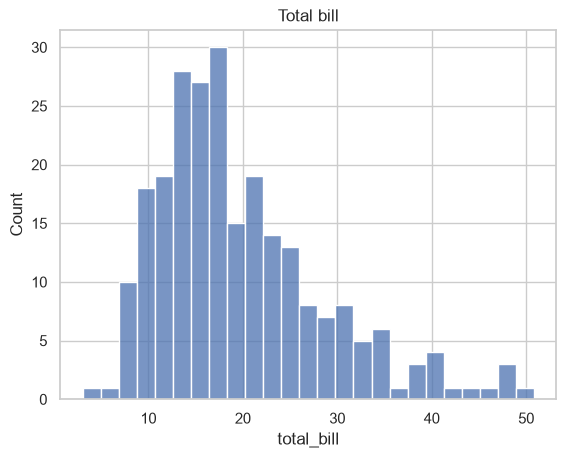

In [13]:
sns.histplot(data=df, x="total_bill", bins=25)
plt.title("Total bill")
plt.show()

Most bills are between 13 and 24 dollars. A few bills are very high, far on the right.

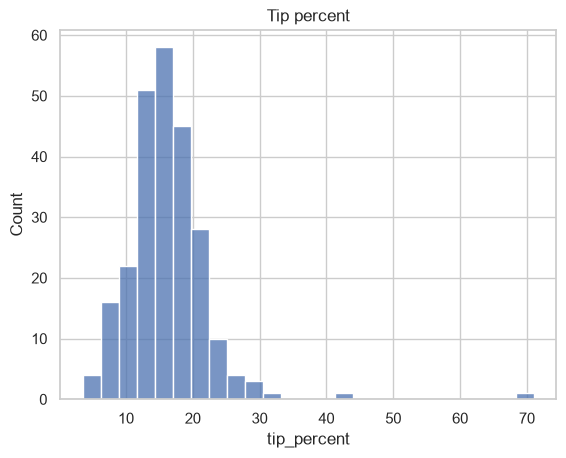

In [14]:
sns.histplot(data=df, x="tip_percent", bins=25)
plt.title("Tip percent")
plt.show()

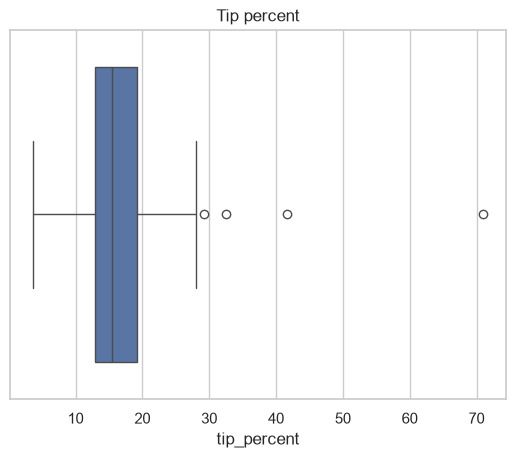

In [18]:
sns.boxplot(data=df, x="tip_percent")
plt.title("Tip percent")
plt.show()

## 5. Findings

### Finding 1: A normal tip is about 15% of the bill

In [19]:
print("Average tip percent:", round(df["tip_percent"].mean(), 1))
print("Median tip percent:", round(df["tip_percent"].median(), 1))
print("Average tip in dollars:", round(df["tip"].mean(), 2))



Average tip percent: 16.1
Median tip percent: 15.5
Average tip in dollars: 3.0


In [22]:
print(df.groupby("size")["tip"].sum().round(2))
print()


size
1      5.75
2    402.84
3    128.94
4    153.01
5     20.14
6     20.90
Name: tip, dtype: float64



In [24]:
print(df.groupby("gender")["tip_percent"].mean().round(1))
print()
print(df.groupby("smoker")["tip_percent"].mean().round(1))
print()
print(df.groupby("gender")["total_bill"].mean().round(2))



gender
Female    16.6
Male      15.8
Name: tip_percent, dtype: float64

smoker
No     15.9
Yes    16.3
Name: tip_percent, dtype: float64

gender
Female    18.06
Male      20.74
Name: total_bill, dtype: float64


## 6. Conclusion
1. A normal tip is about **15 to 16%** of the bill, which is about **3 dollars**.
2. The **bill amount** is what decides the tip the most (correlation **0.68**).
3. Big bills and big tables tip **more dollars**, but a **smaller percent**.
4. **Gender and smoking** do not change the tip percent much (less than 1 to 2 points).
5. The data has **no missing values**. The biggest outlier (71% tip) is real, so we kept it.

**Limit:** we only have 244 bills from one restaurant. Some groups are very small. Correlation does not prove the cause.

**Next month:** in Machine Learning we can teach a model to predict the tip from the bill and the table size.